
--- Fit Parameters for Ansatz: HEA1 (s=1.0) ---
Function: log10(D_KL(p)) = A * tanh(k * (p - p_c)) + B
N    | A (Amplitude)   | k (Steepness)   | p_c (Critical p)  | B (Offset)     
---------------------------------------------------------------------------
6    | 0.9843          | 4.1223          | 0.2945            | -1.2356        
8    | 1.1360          | 4.4906          | 0.2552            | -1.2087        
10   | 1.2021          | 4.7706          | 0.2327            | -1.1406        
12   | 1.1708          | 6.3012          | 0.2300            | -1.0639        
14   | 1.2733          | 5.9291          | 0.2171            | -1.0705        
16   | 1.2947          | 6.6404          | 0.2144            | -1.0482        
18   | 1.3836          | 6.8266          | 0.1996            | -1.0969        


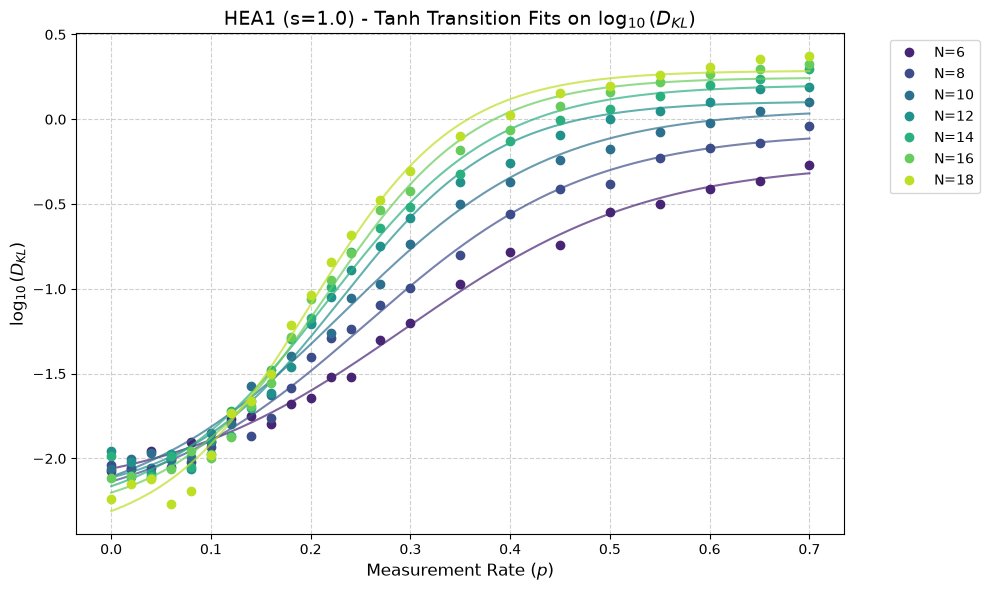


--- Fit Parameters for Ansatz: HEA2 (s=1.0) ---
Function: log10(D_KL(p)) = A * tanh(k * (p - p_c)) + B
N    | A (Amplitude)   | k (Steepness)   | p_c (Critical p)  | B (Offset)     
---------------------------------------------------------------------------
6    | 0.9790          | 4.7655          | 0.2670            | -1.2420        
8    | 1.0956          | 5.1753          | 0.2347            | -1.1919        
10   | 1.2151          | 5.2591          | 0.2065            | -1.1837        
12   | 1.2213          | 5.9618          | 0.2040            | -1.1102        
14   | 1.2570          | 6.0605          | 0.1961            | -1.0724        
16   | 1.3152          | 6.2847          | 0.1856            | -1.0977        
18   | 1.4494          | 6.1426          | 0.1702            | -1.1891        


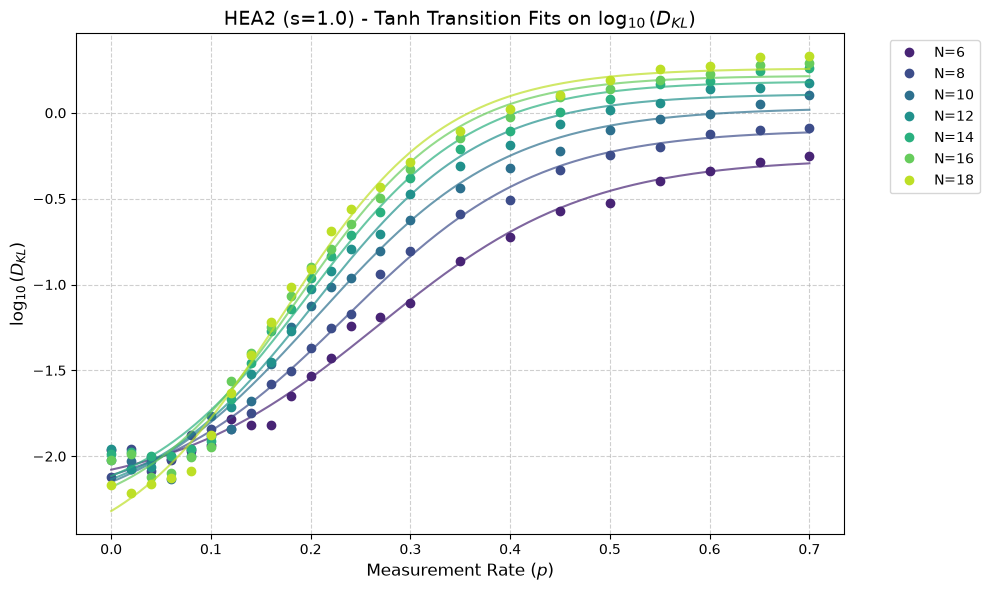

In [2]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 1. Define the target function for the fit
def tanh_fit(p, A, k, p_c, B):
    return A * np.tanh(k * (p - p_c)) + B

# 2. Load the sweep data
data_path = os.path.join("data_exp", "expressibility_sweep_data.pkl")
with open(data_path, "rb") as f:
    data = pickle.load(f)

# Extract lists and the nested dictionary
N_list = data["N_list"]
ansatz_list = data["ansatz_list"]
dkl_by_s = data["dkl_values_by_s"]

s_target = 1.0
if s_target not in dkl_by_s:
    raise ValueError(f"s={s_target} not found in data.")

dkl_s1 = dkl_by_s[s_target]

# 3. Fit and plot log10(D_KL) for each Ansatz
for ansatz in ansatz_list:
    plt.figure(figsize=(10, 6))
    cmap = plt.cm.viridis(np.linspace(0.1, 0.9, len(N_list)))
    
    print(f"\n--- Fit Parameters for Ansatz: {ansatz} (s=1.0) ---")
    print(f"Function: log10(D_KL(p)) = A * tanh(k * (p - p_c)) + B")
    print(f"{'N':<4} | {'A (Amplitude)':<15} | {'k (Steepness)':<15} | {'p_c (Critical p)':<17} | {'B (Offset)':<15}")
    print("-" * 75)
    
    for idx_n, N in enumerate(N_list):
        p_vals = []
        dkl_vals = []
        
        # Aggregate the curve for this specific N
        for p_val in sorted(dkl_s1[ansatz].keys()):
            if N in dkl_s1[ansatz][p_val]:
                p_vals.append(p_val)
                dkl_vals.append(dkl_s1[ansatz][p_val][N])
                
        if not p_vals:
            continue
            
        p_arr = np.array(p_vals)
        dkl_arr = np.array(dkl_vals)
        
        # Transform to log scale (safeguard against zero)
        log_dkl_arr = np.log10(np.maximum(dkl_arr, 1e-15))
        
        # Initial parameter guesses (p0) adapted for the log scale
        max_y, min_y = np.max(log_dkl_arr), np.min(log_dkl_arr)
        A_guess = (max_y - min_y) / 2.0
        B_guess = (max_y + min_y) / 2.0
        p_c_guess = p_arr[np.argmin(np.abs(log_dkl_arr - B_guess))] 
        k_guess = 10.0 
        
        try:
            popt, _ = curve_fit(
                tanh_fit, p_arr, log_dkl_arr, 
                p0=[A_guess, k_guess, p_c_guess, B_guess],
                maxfev=10000
            )
            A_opt, k_opt, pc_opt, B_opt = popt
            
            # Print the parameters
            print(f"{N:<4} | {A_opt:<15.4f} | {k_opt:<15.4f} | {pc_opt:<17.4f} | {B_opt:<15.4f}")
            
            # Generate high-res line for the smooth fit
            p_smooth = np.linspace(min(p_arr), max(p_arr), 200)
            fit_smooth = tanh_fit(p_smooth, *popt)
            
            plt.plot(p_smooth, fit_smooth, color=cmap[idx_n], linestyle="-", alpha=0.7)
            
        except RuntimeError:
            print(f"{N:<4} | Optimal parameters not found (curve_fit failed to converge).")
            
        # Plot raw scatter data over the fit
        plt.plot(p_arr, log_dkl_arr, "o", color=cmap[idx_n], label=f"N={N}")

    plt.title(f"{ansatz} (s=1.0) - Tanh Transition Fits on $\\log_{{10}}(D_{{KL}})$", fontsize=14)
    plt.xlabel("Measurement Rate ($p$)", fontsize=12)
    plt.ylabel(r"$\log_{10}(D_{KL})$", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()


Running bootstrap for HEA1...
Ansatz: HEA1
Optimal p_c : 0.1073 ± 0.0074
Optimal nu  : 1.1130 ± 0.0512


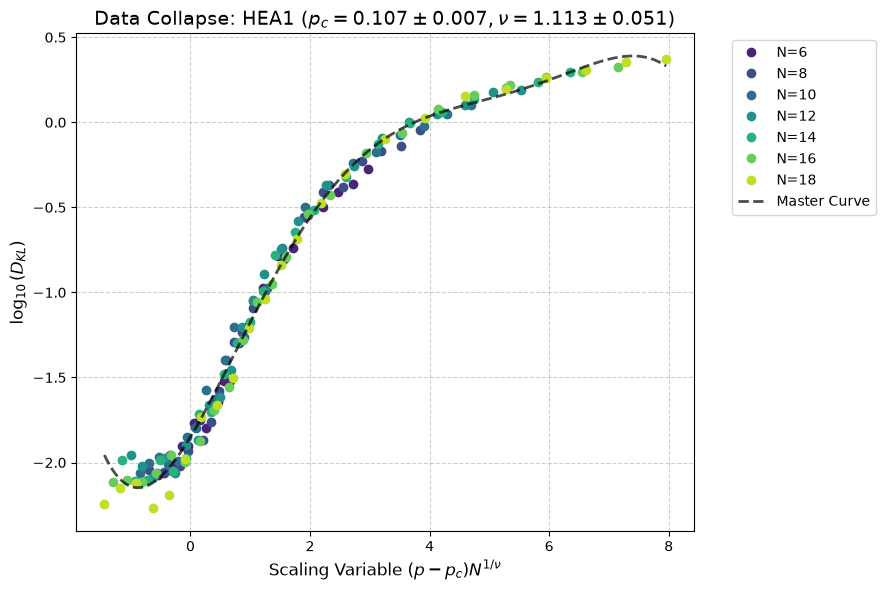


Running bootstrap for HEA2...
Ansatz: HEA2
Optimal p_c : 0.0779 ± 0.0081
Optimal nu  : 1.2750 ± 0.0661


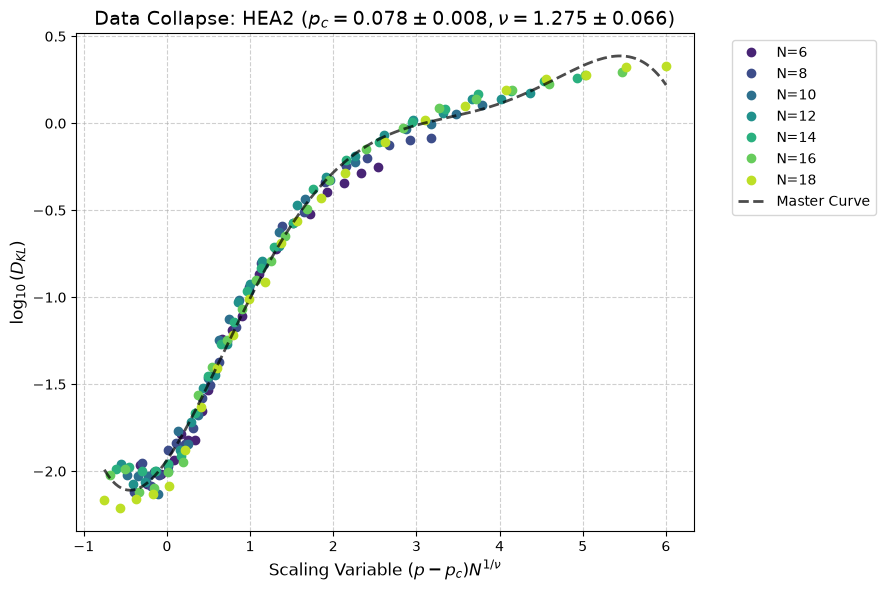

In [7]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# 1. Load the sweep data
data_path = os.path.join("data_exp", "expressibility_sweep_data.pkl")
with open(data_path, "rb") as f:
    data = pickle.load(f)

N_list = data["N_list"]
ansatz_list = data["ansatz_list"]
dkl_by_s = data["dkl_values_by_s"]

s_target = 1.0
dkl_s1 = dkl_by_s[s_target]

# 2. Define the objective function for data collapse
def collapse_cost(params, p_all, y_all, N_all, poly_degree=5):
    p_c, nu = params
    x_scaled = (p_all - p_c) * (N_all ** (1.0 / nu))
    
    # Fit a polynomial to the proposed collapsed data
    poly_coeffs = np.polyfit(x_scaled, y_all, poly_degree)
    poly_func = np.poly1d(poly_coeffs)
    
    y_pred = poly_func(x_scaled)
    mse = np.mean((y_all - y_pred)**2)
    return mse

# 3. Perform collapse and bootstrap for each Ansatz
for ansatz in ansatz_list:
    p_all = []
    y_all = []
    N_all = []
    
    for N in N_list:
        for p_val in sorted(dkl_s1[ansatz].keys()):
            if N in dkl_s1[ansatz][p_val]:
                dkl_val = dkl_s1[ansatz][p_val][N]
                p_all.append(p_val)
                y_all.append(np.log10(max(dkl_val, 1e-15)))
                N_all.append(N)
                
    p_all = np.array(p_all)
    y_all = np.array(y_all)
    N_all = np.array(N_all)
    
    initial_guess = [0.25, 1.2]
    
    # Base Optimization
    res = minimize(
        collapse_cost, 
        initial_guess, 
        args=(p_all, y_all, N_all, 5),
        method='Nelder-Mead',
        options={'maxiter': 2000, 'xatol': 1e-4, 'fatol': 1e-4}
    )
    
    best_pc, best_nu = res.x
    
    # 4. Statistical Bootstrapping for Error Estimation
    print(f"\nRunning bootstrap for {ansatz}...")
    K_boot = 100
    n_samples = len(p_all)
    pc_boot = []
    nu_boot = []
    
    for _ in range(K_boot):
        # Sample with replacement
        indices = np.random.choice(n_samples, size=n_samples, replace=True)
        p_boot = p_all[indices]
        y_boot = y_all[indices]
        N_boot_arr = N_all[indices]
        
        boot_res = minimize(
            collapse_cost, 
            [best_pc, best_nu], # Start near the known best to speed up
            args=(p_boot, y_boot, N_boot_arr, 5),
            method='Nelder-Mead',
            options={'maxiter': 1000, 'xatol': 1e-3, 'fatol': 1e-3}
        )
        pc_boot.append(boot_res.x[0])
        nu_boot.append(boot_res.x[1])
        
    pc_err = np.std(pc_boot)
    nu_err = np.std(nu_boot)
    
    print(f"Ansatz: {ansatz}")
    print(f"Optimal p_c : {best_pc:.4f} ± {pc_err:.4f}")
    print(f"Optimal nu  : {best_nu:.4f} ± {nu_err:.4f}")
    
    # Plot the collapsed data
    plt.figure(figsize=(9, 6))
    cmap = plt.cm.viridis(np.linspace(0.1, 0.9, len(N_list)))
    
    for idx_n, N in enumerate(N_list):
        mask = N_all == N
        x_scaled = (p_all[mask] - best_pc) * (N ** (1.0 / best_nu))
        plt.plot(x_scaled, y_all[mask], "o", color=cmap[idx_n], label=f"N={N}")
        
    # Plot the fitted master curve
    x_grid = np.linspace(np.min((p_all - best_pc) * (N_all ** (1.0 / best_nu))), 
                         np.max((p_all - best_pc) * (N_all ** (1.0 / best_nu))), 200)
    poly_coeffs = np.polyfit((p_all - best_pc) * (N_all ** (1.0 / best_nu)), y_all, 5)
    plt.plot(x_grid, np.poly1d(poly_coeffs)(x_grid), 'k--', lw=2, label="Master Curve", alpha=0.7)

    plt.title(f"Data Collapse: {ansatz} ($p_c={best_pc:.3f} \\pm {pc_err:.3f}, \\nu={best_nu:.3f} \\pm {nu_err:.3f}$)", fontsize=14)
    plt.xlabel(r"Scaling Variable $(p - p_c)N^{1/\nu}$", fontsize=12)
    plt.ylabel(r"$\log_{10}(D_{KL})$", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()


Running bootstrap for HEA1...
Ansatz: HEA1
Optimal p_c : 0.1527 ± 0.0161
Optimal nu  : 1.1055 ± 0.0819


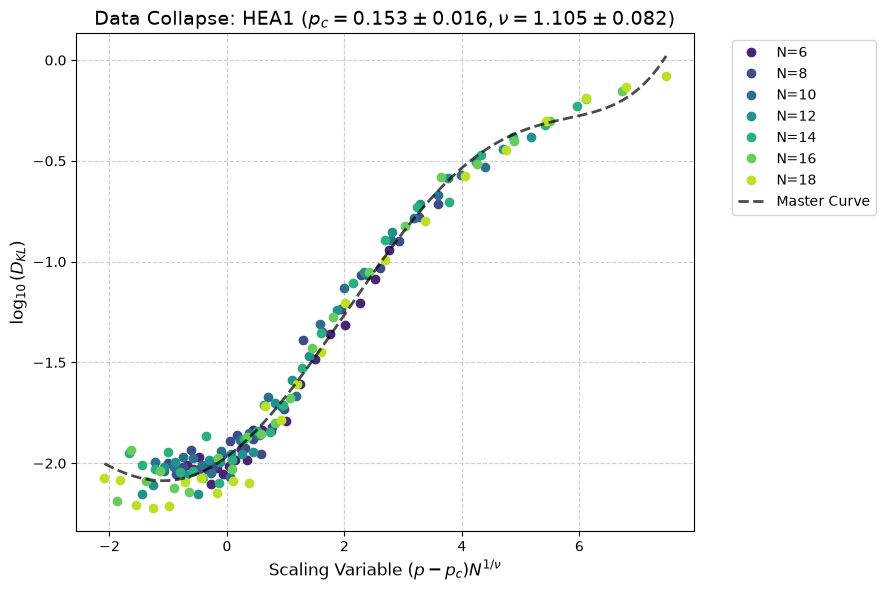


Running bootstrap for HEA2...
Ansatz: HEA2
Optimal p_c : 0.1053 ± 0.0287
Optimal nu  : 1.3738 ± 0.1551


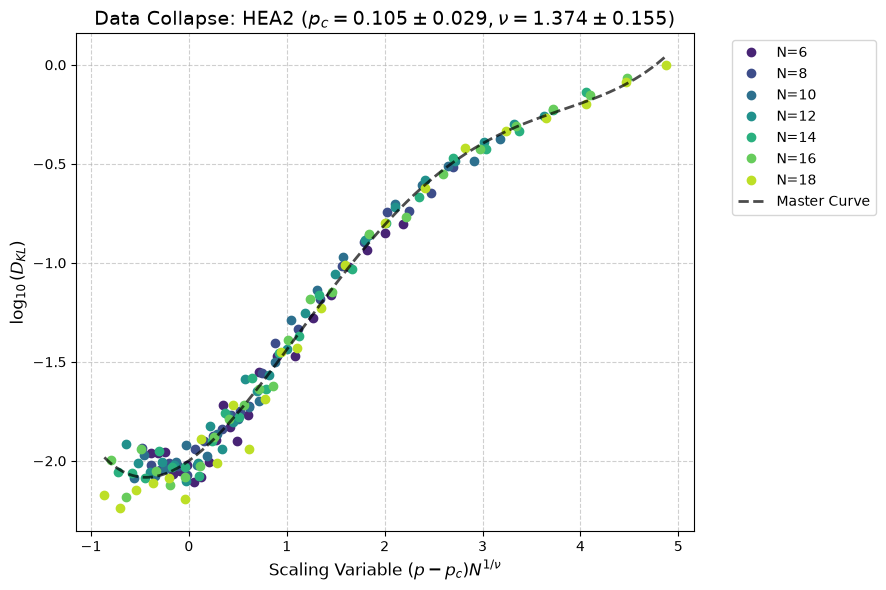

In [8]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# 1. Load the sweep data
data_path = os.path.join("data_exp", "expressibility_sweep_data.pkl")
with open(data_path, "rb") as f:
    data = pickle.load(f)

N_list = data["N_list"]
ansatz_list = data["ansatz_list"]
dkl_by_s = data["dkl_values_by_s"]

s_target = 0.5
dkl_s1 = dkl_by_s[s_target]

# 2. Define the objective function for data collapse
def collapse_cost(params, p_all, y_all, N_all, poly_degree=5):
    p_c, nu = params
    x_scaled = (p_all - p_c) * (N_all ** (1.0 / nu))
    
    # Fit a polynomial to the proposed collapsed data
    poly_coeffs = np.polyfit(x_scaled, y_all, poly_degree)
    poly_func = np.poly1d(poly_coeffs)
    
    y_pred = poly_func(x_scaled)
    mse = np.mean((y_all - y_pred)**2)
    return mse

# 3. Perform collapse and bootstrap for each Ansatz
for ansatz in ansatz_list:
    p_all = []
    y_all = []
    N_all = []
    
    for N in N_list:
        for p_val in sorted(dkl_s1[ansatz].keys()):
            if N in dkl_s1[ansatz][p_val]:
                dkl_val = dkl_s1[ansatz][p_val][N]
                p_all.append(p_val)
                y_all.append(np.log10(max(dkl_val, 1e-15)))
                N_all.append(N)
                
    p_all = np.array(p_all)
    y_all = np.array(y_all)
    N_all = np.array(N_all)
    
    initial_guess = [0.25, 1.2]
    
    # Base Optimization
    res = minimize(
        collapse_cost, 
        initial_guess, 
        args=(p_all, y_all, N_all, 5),
        method='Nelder-Mead',
        options={'maxiter': 2000, 'xatol': 1e-4, 'fatol': 1e-4}
    )
    
    best_pc, best_nu = res.x
    
    # 4. Statistical Bootstrapping for Error Estimation
    print(f"\nRunning bootstrap for {ansatz}...")
    K_boot = 100
    n_samples = len(p_all)
    pc_boot = []
    nu_boot = []
    
    for _ in range(K_boot):
        # Sample with replacement
        indices = np.random.choice(n_samples, size=n_samples, replace=True)
        p_boot = p_all[indices]
        y_boot = y_all[indices]
        N_boot_arr = N_all[indices]
        
        boot_res = minimize(
            collapse_cost, 
            [best_pc, best_nu], # Start near the known best to speed up
            args=(p_boot, y_boot, N_boot_arr, 5),
            method='Nelder-Mead',
            options={'maxiter': 1000, 'xatol': 1e-3, 'fatol': 1e-3}
        )
        pc_boot.append(boot_res.x[0])
        nu_boot.append(boot_res.x[1])
        
    pc_err = np.std(pc_boot)
    nu_err = np.std(nu_boot)
    
    print(f"Ansatz: {ansatz}")
    print(f"Optimal p_c : {best_pc:.4f} ± {pc_err:.4f}")
    print(f"Optimal nu  : {best_nu:.4f} ± {nu_err:.4f}")
    
    # Plot the collapsed data
    plt.figure(figsize=(9, 6))
    cmap = plt.cm.viridis(np.linspace(0.1, 0.9, len(N_list)))
    
    for idx_n, N in enumerate(N_list):
        mask = N_all == N
        x_scaled = (p_all[mask] - best_pc) * (N ** (1.0 / best_nu))
        plt.plot(x_scaled, y_all[mask], "o", color=cmap[idx_n], label=f"N={N}")
        
    # Plot the fitted master curve
    x_grid = np.linspace(np.min((p_all - best_pc) * (N_all ** (1.0 / best_nu))), 
                         np.max((p_all - best_pc) * (N_all ** (1.0 / best_nu))), 200)
    poly_coeffs = np.polyfit((p_all - best_pc) * (N_all ** (1.0 / best_nu)), y_all, 5)
    plt.plot(x_grid, np.poly1d(poly_coeffs)(x_grid), 'k--', lw=2, label="Master Curve", alpha=0.7)

    plt.title(f"Data Collapse: {ansatz} ($p_c={best_pc:.3f} \\pm {pc_err:.3f}, \\nu={best_nu:.3f} \\pm {nu_err:.3f}$)", fontsize=14)
    plt.xlabel(r"Scaling Variable $(p - p_c)N^{1/\nu}$", fontsize=12)
    plt.ylabel(r"$\log_{10}(D_{KL})$", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()


--- Fit Parameters for Ansatz: HEA2 (s=1.0) ---
Function: log10(D_KL(p)) = A * tanh(k * (p - p_c)) + B
N    | A (Amplitude)   | k (Steepness)   | p_c (Critical p)  | B (Offset)     
---------------------------------------------------------------------------
6    | 0.9790          | 4.7655          | 0.2670            | -1.2420        
8    | 1.0956          | 5.1753          | 0.2347            | -1.1919        
10   | 1.2151          | 5.2591          | 0.2065            | -1.1837        
12   | 1.2213          | 5.9618          | 0.2040            | -1.1102        
14   | 1.2570          | 6.0605          | 0.1961            | -1.0724        
16   | 1.3152          | 6.2847          | 0.1856            | -1.0977        
18   | 1.4494          | 6.1426          | 0.1702            | -1.1891        

Figure saved successfully to: HEA2_logDKL_vs_p_IEEE.pdf


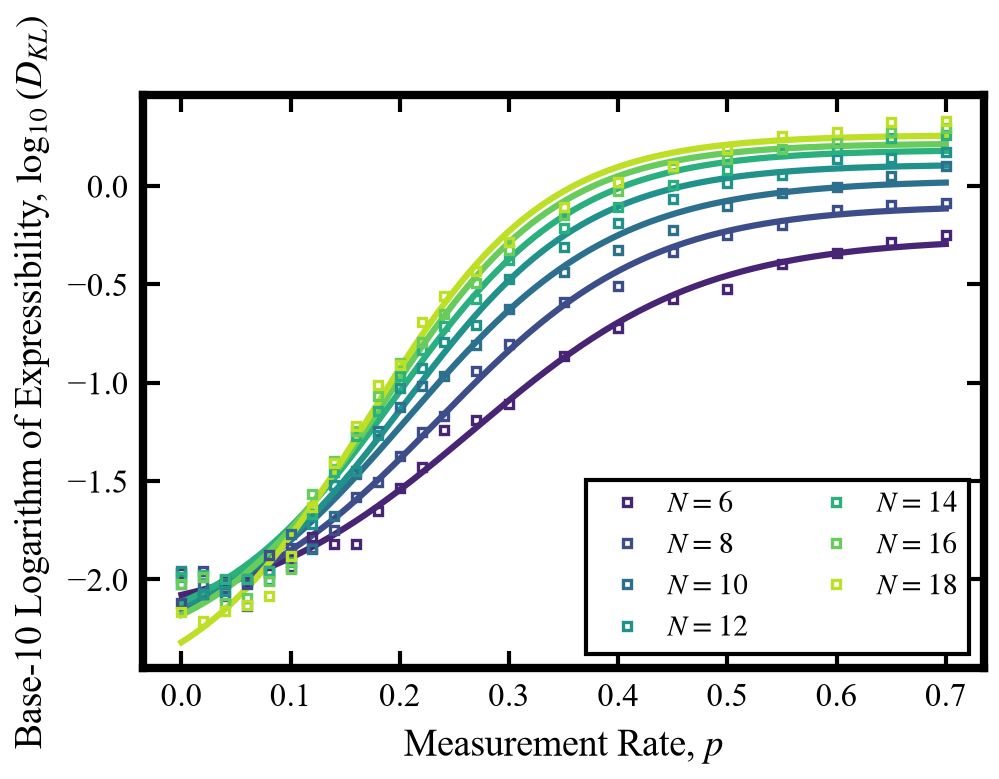

In [4]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import curve_fit

# =============================================================================
# IEEE CONFERENCE MATPLOTLIB SETTINGS
# =============================================================================
mpl.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'mathtext.fontset': 'stix',         # Matches Times New Roman math styling
    'axes.labelsize': 9,                
    'font.size': 9,                     
    'legend.fontsize': 7,               # Smaller font to fit double-column width
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'xtick.direction': 'in',            
    'ytick.direction': 'in',
    'xtick.top': True,                  
    'ytick.right': True,                
    'axes.linewidth': 2.0,              # Thick borders 
    'lines.linewidth': 1.5,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.05
})

# 1. Define the target function for the fit
def tanh_fit(p, A, k, p_c, B):
    return A * np.tanh(k * (p - p_c)) + B

def plot_ieee_expressibility_fit(
    data_path=os.path.join("data_exp", "expressibility_sweep_data.pkl"),
    target_ansatz="HEA2",
    s_target=1.0,
    save_path="HEA2_logDKL_vs_p_IEEE.pdf"
):
    # 2. Load the sweep data
    with open(data_path, "rb") as f:
        data = pickle.load(f)

    N_list = data["N_list"]
    dkl_by_s = data["dkl_values_by_s"]

    if s_target not in dkl_by_s:
        raise ValueError(f"s={s_target} not found in data.")

    dkl_s1 = dkl_by_s[s_target]
    
    if target_ansatz not in dkl_s1:
        raise ValueError(f"Ansatz {target_ansatz} not found in data for s={s_target}.")

    # 3. Setup the Figure
    fig, ax = plt.subplots(figsize=(3.5, 2.5)) 
    cmap = plt.cm.viridis(np.linspace(0.1, 0.9, len(N_list)))
    
    print(f"\n--- Fit Parameters for Ansatz: {target_ansatz} (s={s_target}) ---")
    print(f"Function: log10(D_KL(p)) = A * tanh(k * (p - p_c)) + B")
    print(f"{'N':<4} | {'A (Amplitude)':<15} | {'k (Steepness)':<15} | {'p_c (Critical p)':<17} | {'B (Offset)':<15}")
    print("-" * 75)
    
    for idx_n, N in enumerate(N_list):
        p_vals = []
        dkl_vals = []
        
        # Aggregate the curve for this specific N
        for p_val in sorted(dkl_s1[target_ansatz].keys()):
            if N in dkl_s1[target_ansatz][p_val]:
                p_vals.append(p_val)
                dkl_vals.append(dkl_s1[target_ansatz][p_val][N])
                
        if not p_vals:
            continue
            
        p_arr = np.array(p_vals)
        dkl_arr = np.array(dkl_vals)
        
        # Transform to log scale (safeguard against zero)
        log_dkl_arr = np.log10(np.maximum(dkl_arr, 1e-15))
        
        # Initial parameter guesses (p0) adapted for the log scale
        max_y, min_y = np.max(log_dkl_arr), np.min(log_dkl_arr)
        A_guess = (max_y - min_y) / 2.0
        B_guess = (max_y + min_y) / 2.0
        p_c_guess = p_arr[np.argmin(np.abs(log_dkl_arr - B_guess))] 
        k_guess = 10.0 
        
        try:
            popt, _ = curve_fit(
                tanh_fit, p_arr, log_dkl_arr, 
                p0=[A_guess, k_guess, p_c_guess, B_guess],
                maxfev=10000
            )
            A_opt, k_opt, pc_opt, B_opt = popt
            print(f"{N:<4} | {A_opt:<15.4f} | {k_opt:<15.4f} | {pc_opt:<17.4f} | {B_opt:<15.4f}")
            
            # Generate high-res line for the smooth fit
            p_smooth = np.linspace(min(p_arr), max(p_arr), 200)
            fit_smooth = tanh_fit(p_smooth, *popt)
            
            # Plot the smooth fit line
            ax.plot(p_smooth, fit_smooth, color=cmap[idx_n], linestyle="-", zorder=1)
            
        except RuntimeError:
            print(f"{N:<4} | Optimal parameters not found (curve_fit failed to converge).")
            
        # Plot raw scatter data over the fit (using hollow squares to match previous IEEE plots)
        ax.plot(p_arr, log_dkl_arr, marker="s", linestyle="none", color=cmap[idx_n], 
                label=f"$N = {N}$", markerfacecolor='none', markersize=2.0, markeredgewidth=0.8, zorder=2)

    # 4. Formatting Axes and Labels strictly to IEEE text-based rules
    ax.set_xlabel("Measurement Rate, $p$")
    ax.set_ylabel(r"Base-10 Logarithm of Expressibility, $\log_{10}(D_{KL})$")
    
    # Tick mark styling
    ax.tick_params(axis='both', which='major', width=1.0, length=4.0)

    # Grid removed to match IEEE sample standard
    ax.grid(False)
    
    # Split legend into 2 columns if there are many N values to save space
    ax.legend(
        loc="best", 
        ncol=2 if len(N_list) > 4 else 1, 
        frameon=True, 
        edgecolor='black', 
        fancybox=False, 
        framealpha=1.0,
        handletextpad=0.4
    )

    plt.tight_layout()
    
    # 5. Save and Show
    if save_path:
        plt.savefig(save_path)
        print(f"\nFigure saved successfully to: {save_path}")
        
    plt.show()

# =============================================================================
# EXECUTE FOR HEA2
# =============================================================================
if __name__ == "__main__":
    plot_ieee_expressibility_fit(
        data_path=os.path.join("data_exp", "expressibility_sweep_data.pkl"),
        target_ansatz="HEA2",
        s_target=1.0,
        save_path="HEA2_logDKL_vs_p_IEEE.pdf"
    )